In [3]:
from pathlib import Path
import sys

root_dir = Path.cwd().resolve().parents[1]
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

from materials_vision.inspection import load_run_curves, training_curves_figure

%matplotlib inline

### Values accepted by `metric` in `load_run_curves`

All are read per epoch on VALIDATION (and as a single point on TEST, where one was scored), under the chosen post-processing setting.

**Detection**
- `f1`: instance F1, counts pooled over all images (default; the headline metric)
- `precision`: fraction of predicted pores matched to an annotated pore
- `recall`: fraction of annotated pores matched by a prediction
- `macro_f1`: F1 per image, averaged over images

**Overlap and outlines**
- `mean_pair_iou`: mean IoU of the matched pairs
- `boundary_f1`: outline agreement at a tolerance of 0.1 × mean pore diameter

**Separation**
- `merges_per_100_gt`: predictions fusing two or more annotated pores, per 100 annotated pores
- `splits_per_100_gt`: annotated pores cut into two or more predictions, per 100 annotated pores

**Pore count**
- `pore_count_error`: (n_pred − n_gt) / n_gt, pooled; signed fraction, not percent
- `macro_abs_pore_count_error`: absolute count error per image, averaged
- `n_gt`, `n_pred`: annotated and predicted pore counts (n_gt is constant across epochs)

**Size and shape**
- `median_diameter_error`: median |d_pred − d_gt| / d_gt over matched pairs
- `median_diameter_log_ratio`: median log(d_pred / d_gt) over matched pairs; positive = pores drawn too large. *Only in runs scored after this field was added (the part-II runs); older runs return an empty curve.*
- `median_elongation_error`: median relative elongation error over matched pairs

**Material quantities (natural units, not % of annotation)**
- `mean_porosity_error_pp`: porosity error in percentage points, averaged over images
- `median_diameter_drift_um`: shift of the median pore diameter, in µm
- `wasserstein_um`: distance between predicted and annotated diameter distributions, in µm

Values for `loss`: `instance_loss` (default; decoder the segmentation comes from), `loss`, `mask_loss`, `iou_loss`.
Values for `postprocessing`: `"frozen"` (default; the only setting with both VAL curves and TEST points), `"calibrated_2026_09_24"`, `"deployed"` (no per-epoch curves stored), or a `WatershedParams`.


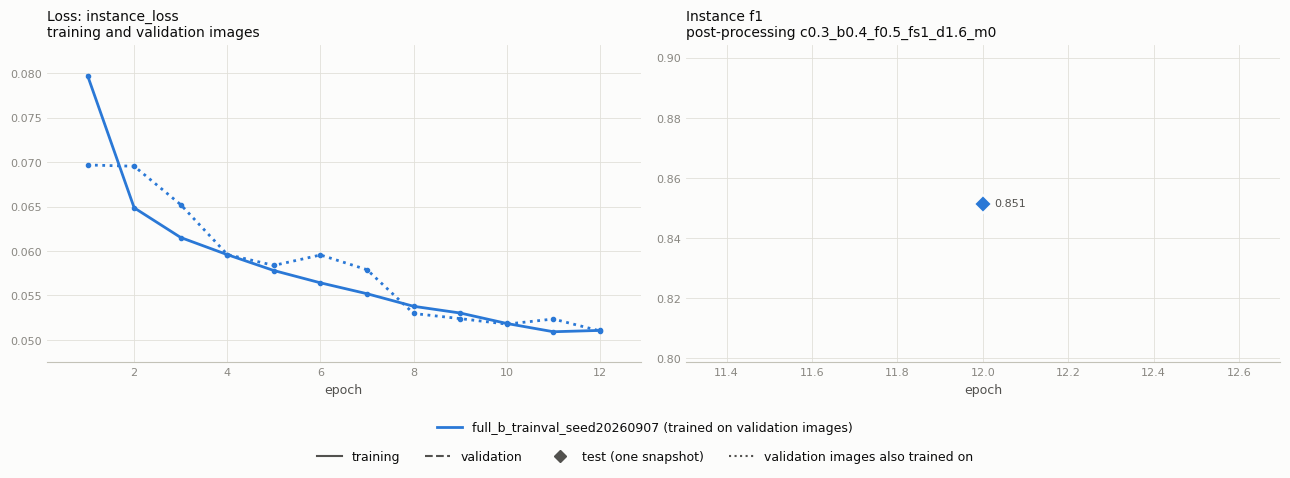

In [ ]:
training_curves_figure([
    # load_run_curves("b0_seed20260907"),
      load_run_curves("d4_seed20260907"),
    # load_run_curves("full_b_trainval_seed20260907"),
])

In [8]:
load_run_curves("d4_seed20260908", metric="merges_per_100_gt",
                postprocessing="calibrated_2026_09_24");